In [1]:
import math
from decimal import Decimal, getcontext

import matplotlib.pyplot as plt


## Questão 2

Vamos usar a biblioteca `decimal` do Python, configurando a precisão para $k = 4$ dígitos significativos. Como cada operação aritmética sobre um `Decimal` já é arredondada automaticamente para a precisão definida no contexto, isso satisfaz a exigência de arredondamento após cada operação.

### a) Polinômio de Maclaurin de grau 8 para $f(x) = \cos(x)$

A série de Maclaurin de $\cos(x)$ é

$$\cos(x) = \sum_{n=0}^{\infty} (-1)^n \frac{x^{2n}}{(2n)!}$$

Tomando os termos até grau 8 ($n = 0, 1, 2, 3, 4$):

$$P_8(x) = 1 - \frac{x^2}{2!} + \frac{x^4}{4!} - \frac{x^6}{6!} + \frac{x^8}{8!}$$

In [2]:

getcontext().prec = 4

def factorial(n: int) -> int:
    r = 1
    for i in range(1, n + 1):
        r *= i
    return r

coefs = []
for n in range(5):
    sinal = Decimal(1) if n % 2 == 0 else Decimal(-1)
    coef = sinal / Decimal(factorial(2 * n))
    coefs.append(coef)
    print(f"n={n}, termo x^{2*n}, coeficiente = {coef}")

n=0, termo x^0, coeficiente = 1
n=1, termo x^2, coeficiente = -0.5
n=2, termo x^4, coeficiente = 0.04167
n=3, termo x^6, coeficiente = -0.001389
n=4, termo x^8, coeficiente = 0.00002480


Ou seja, com $k = 4$ dígitos:

$$P_8(x) \approx 1 - 0{,}5000\,x^2 + 0{,}04167\,x^4 - 0{,}001389\,x^6 + 0{,}00002480\,x^8$$

### b) Aproximação de $\cos(0{,}5)$ sem aninhamento

Calculamos cada potência de $x$ separadamente, multiplicamos pelo coeficiente correspondente e somamos os termos ao final.

In [3]:
x = Decimal('0.5')
op_b = 0

x2 = x * x; op_b += 1
x4 = x2 * x2; op_b += 1
x6 = x4 * x2; op_b += 1
x8 = x4 * x4; op_b += 1

t0 = coefs[0]
t1 = coefs[1] * x2; op_b += 1
t2 = coefs[2] * x4; op_b += 1
t3 = coefs[3] * x6; op_b += 1
t4 = coefs[4] * x8; op_b += 1

sum_no_nesting = t0
sum_no_nesting = sum_no_nesting + t1; op_b += 1
sum_no_nesting = sum_no_nesting + t2; op_b += 1
sum_no_nesting = sum_no_nesting + t3; op_b += 1
sum_no_nesting = sum_no_nesting + t4; op_b += 1

print(f"Termos: {t0}, {t1}, {t2}, {t3}, {t4}")
print(f"Aproximação sem aninhamento: {sum_no_nesting}")
print(f"Número de operações: {op_b}")

Termos: 1, -0.125, 0.002604, -0.00002170, 9.687E-8
Aproximação sem aninhamento: 0.8776
Número de operações: 12


### c) Forma aninhada (Horner)

Como só aparecem potências pares de $x$, fazemos $u = x^2$, reduzindo $P_8$ a um polinômio de grau 4 em $u$: $P_8 = c_0 + c_1u + c_2u^2 + c_3u^3 + c_4u^4$.

A forma aninhada (Horner) coloca $u$ em evidência sucessivamente:

$$c_0 + c_1u + c_2u^2 + c_3u^3 + c_4u^4 = c_0 + u\big(c_1 + u(c_2 + u(c_3 + c_4u))\big)$$

Substituindo os coeficientes $c_0, \dots, c_4$:

$$P_8(x) = 1 + u\left(-\frac{1}{2} + u\left(\frac{1}{24} + u\left(-\frac{1}{720} + u\cdot\frac{1}{40320}\right)\right)\right)$$

Assim, cada nível do parêntese só exige uma multiplicação por $u$ e uma soma com o coeficiente seguinte, reaproveitando o resultado, usando menos operações que a do item b.

### d) Aproximação de $\cos(0{,}5)$ com a forma aninhada

In [4]:
op_d = 0

u = x * x; op_d += 1
p = coefs[4]
p = u * p; op_d += 1
p = p + coefs[3]; op_d += 1
p = u * p; op_d += 1
p = p + coefs[2]; op_d += 1
p = u * p; op_d += 1
p = p + coefs[1]; op_d += 1
p = u * p; op_d += 1
sum_nesting = p + coefs[0]; op_d += 1

print(f"Aproximação com forma aninhada: {sum_nesting}")
print(f"Número de operações: {op_d}")

Aproximação com forma aninhada: 0.8776
Número de operações: 9


In [5]:
valor_exato = math.cos(0.5)
print(f"Valor exato de cos(0.5): {valor_exato}")
print(f"Erro (sem aninhamento): {abs(Decimal(str(valor_exato)) - sum_no_nesting)}")
print(f"Erro (forma aninhada): {abs(Decimal(str(valor_exato)) - sum_nesting)}")

Valor exato de cos(0.5): 0.8775825618903728
Erro (sem aninhamento): 0.00001744
Erro (forma aninhada): 0.00001744


### e) Comparação

As duas formas chegaram ao mesmo resultado, $0{,}8776$, com o mesmo erro em relação ao valor exato ($\approx 0{,}00001744$), já que a aritmética decimal com $k=4$ dígitos arredonda os resultados intermediários da mesma maneira em ambos os casos e as duas expressões são algebricamente equivalentes.

A diferença está no número de operações aritméticas: a forma sem aninhamento precisou de 12 operações (4 multiplicações para as potências de $x$, 4 multiplicações pelos coeficientes e 4 adições), enquanto a forma aninhada precisou de apenas 9 operações (1 multiplicação para obter $u = x^2$, mais 4 multiplicações e 4 adições).

Ou seja, com menos operações conseguimos o mesmo resultado.

## Questão 4
### a) Função de plotagem

A função abaixo recebe `f`, `a`, `b` e `n`, amostra o domínio $[a, b]$ uniformemente com $n$ pontos e plota $y = f(x)$ usando segmentos de reta entre os pontos amostrados.

In [6]:
def plot_function(f, a, b, n, ax=None, title="Gráfico de f(x)", label=None):
    xs = [a + i * (b - a) / (n - 1) for i in range(n)]
    ys = [f(x) for x in xs]

    standalone = ax is None
    if standalone:
        ax = plt.gca()

    ax.plot(xs, ys, label=label)
    ax.set_xlabel("x")
    ax.set_ylabel("f(x)")
    ax.set_title(title)
    ax.grid(True)

    if standalone:
        plt.show()

Para deixar mais evidente o efeito de $n$, vamos plotar $f(x) = \sin(x) + 0{,}5\sin(8x)$ com três valores de $n$, um ao lado do outro. Com poucos pontos a amostragem não consegue capturar as oscilações de maior frequência, com mais pontos a curva converge para o formato real de $f$.

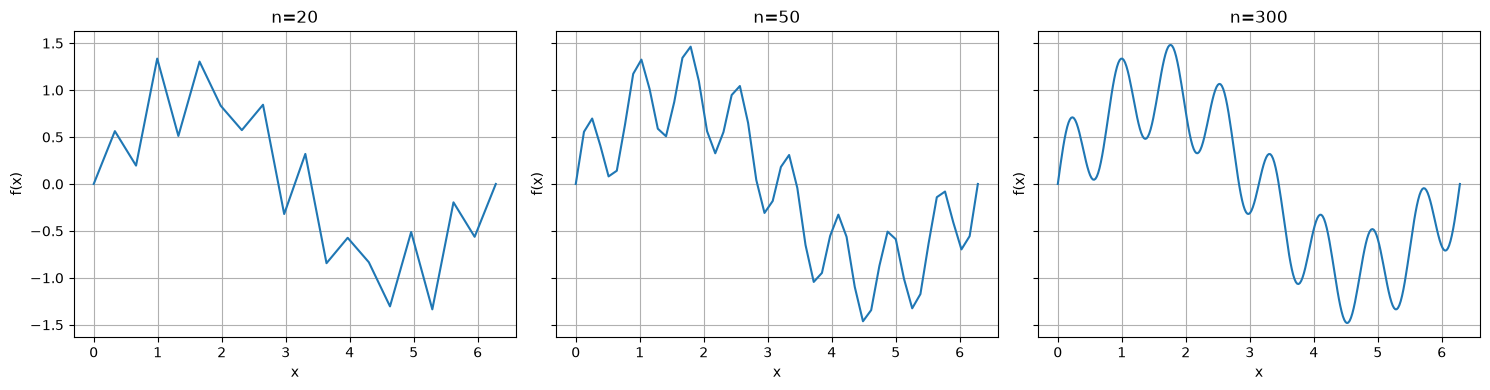

In [7]:
def f_combo(x):
    return math.sin(x) + 0.5 * math.sin(8 * x)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, n in zip(axes, (20, 50, 300)):
    plot_function(f_combo, 0, 2 * math.pi, n, ax=ax, title=f"n={n}")
plt.tight_layout()
plt.show()

### b) Sequência de aproximações da bisseção

Alteramos o algoritmo da questão 3b para retornar a lista de aproximações $p_n$ em vez de apenas a raiz, e implementamos uma função que plota $y = f(x)$ junto com os pontos $(p_n, f(p_n))$.

In [8]:
def bisection_sequence(f, a, b, tol=1e-6, max_iter=100):
    if a >= b or tol <= 0 or max_iter <= 0:
        return None

    fa = f(a)
    fb = f(b)

    if fa == 0:
        return [a]
    if fb == 0:
        return [b]
    if fa * fb > 0:
        return None

    ps = []
    p_prev = None

    for _ in range(max_iter):
        p = a + (b - a) / 2
        ps.append(p)
        fp = f(p)

        if fp == 0:
            return ps

        if p_prev is not None and abs(p - p_prev) < tol:
            return ps

        if fa * fp > 0:
            a, fa = p, fp
        else:
            b = p

        p_prev = p

    return None

In [9]:
def plot_function_with_sequence(f, a, b, n, ps):
    ax = plt.gca()
    plot_function(f, a, b, n, ax=ax, title="Sequência de aproximações da bisseção", label="f(x)")
    ax.scatter(ps, [f(p) for p in ps], color="red", zorder=5, label="$p_n$")
    ax.legend()
    plt.show()

Aplicando em $\ln(x) - 2^x + x^2 - 1 = 0$ no intervalo $[3, 5]$:

Número de iterações: 21
Raiz aproximada: 4.120697975158691


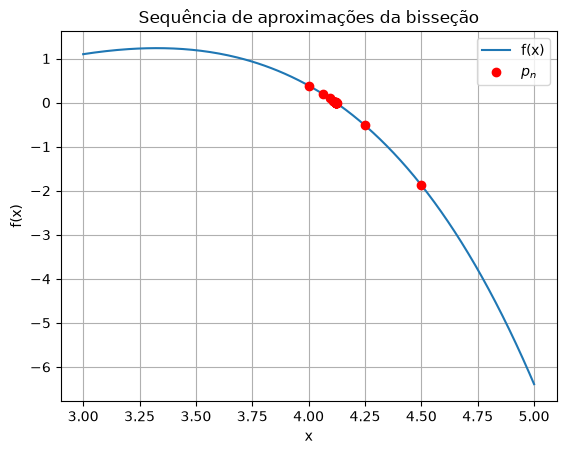

In [10]:
def f_q4(x):
    return math.log(x) - 2 ** x + x ** 2 - 1

ps = bisection_sequence(f_q4, 3, 5, tol=1e-6, max_iter=100)
print(f"Número de iterações: {len(ps)}")
print(f"Raiz aproximada: {ps[-1]}")

plot_function_with_sequence(f_q4, 3, 5, 200, ps)

## Questão 6

Considere $f(x) = x^3 - 2x - 5 = 0$, com $f'(x) = 3x^2 - 2$.

### a) Método de Newton

In [11]:
def f6(x: float) -> float:
    return x ** 3 - 2 * x - 5

def df6(x: float) -> float:
    return 3 * x ** 2 - 2

def newton(f, df, x0, tol=1e-6, max_iter=100, verbose=False):
    x = x0

    for i in range(1, max_iter + 1):
        fx = f(x)
        dfx = df(x)

        if dfx == 0:
            return None, i

        x_new = x - fx / dfx

        if verbose:
            print(f"    {str(i).zfill(4)}: {x_new}")

        if abs(x_new - x) < tol:
            return x_new, i

        x = x_new

    return None, max_iter

### b) Aplicação com $x_0 = 2$ e tolerância $10^{-6}$

In [12]:
raiz_newton, it_newton = newton(f6, df6, x0=2, tol=1e-6, verbose=True)
print(f"Raiz (Newton): {raiz_newton}")
print(f"Número de iterações: {it_newton}")

    0001: 2.1
    0002: 2.094568121104185
    0003: 2.094551481698199
    0004: 2.0945514815423265
Raiz (Newton): 2.0945514815423265
Número de iterações: 4


### c) Método da Bissecção no intervalo $[2, 3]$, mesma tolerância


### d) Comparação

Os dois métodos convergiram para praticamente a mesma raiz, $x \approx 2{,}09455$, com diferença da ordem de $10^{-6}$ entre si (compatível com a tolerância usada). No entanto, o número de iterações necessárias foi muito diferente: o **Método de Newton** convergiu em apenas **4 iterações**, enquanto o **Método da Bissecção** precisou de **20 iterações** para atingir a mesma tolerância.

Isso ocorre porque o Método de Newton tem convergência quadrática (usa a derivada de $f$ para direcionar a busca), enquanto a Bissecção tem convergência apenas linear, reduzindo o intervalo pela metade a cada iteração independentemente do formato da função.